# Notebook 05: Pemilihan Sampel, Target Proksi, dan Pembagian Fold

Menindaklanjuti bukti audit di `04_data_validation.ipynb` dan ketiadaan kolom relaps/BPRS yang ditemukan di `03_data_discovery.ipynb`, notebook ini mengambil tiga keputusan paling menentukan dalam desain eksperimen:

1. **Kelayakan Hari & Gerbang `ABSTAIN`**: Memisahkan mana hari yang sah menjadi titik prediksi dan mana hari yang harus dilewati karena sensor terlalu banyak mati.
2. **Definisi Label Proksi (`PROXY`) & Penyangga 7 Hari**: Karena tidak ada catatan rawat inap/relaps klinis, kita **tidak boleh mengklaim model memprediksi relaps klinis**. Sebagai gantinya, kita mendefinisikan target secara jujur sebagai **lonjakan gejala negatif EMA di atas standar pribadi pasien** dalam jendela `14 hari` ke depan (**`HORIZON_DAYS = 14`**), disertai penyangga **7 hari (`buffer`)** di sekitar hari sakit aktif agar model belajar memprediksi *sebelum* gejala memuncak, bukan mendeteksi orang yang *sedang* sakit hari ini!
3. **Skema Pemisahan Subjek (`StratifiedGroupKFold`)**: Mengunci pembagian 5 fold per individu sebelum data dibersihkan atau fitur dihitung agar proses uji bebas kebocoran selamanya.

Sel pertama memuat data mentah dan mengunci konstanta `HORIZON_DAYS = 14`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

with open(ROOT / "config.json", "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

SEED = int(CONFIG["project"]["seed"])
HORIZON_DAYS = int(CONFIG["modeling_defaults"]["shift_horizon_days"])
DATA_RAW = ROOT / CONFIG["paths"]["data_raw"]
DATA_INTERIM = ROOT / CONFIG["paths"]["data_interim"]
REPORTS_DIR = ROOT / CONFIG["paths"]["reports"]
FIGURES_DIR = ROOT / CONFIG["paths"]["artifacts_figures"]
DATA_INTERIM.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def clean_sas_zeros(df: pd.DataFrame) -> pd.DataFrame:
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols] = df[num_cols].where(df[num_cols].abs() >= 1e-12, 0.0)
    return df


df_cc = pd.read_csv(DATA_RAW / "crosscheck" / "crosscheck_daily_data_cleaned_w_sameday.csv")
df_sl = pd.read_csv(DATA_RAW / "studentlife" / "studentlife_daily_data_cleaned_w_sameday_08282021.csv")
df_paxday = clean_sas_zeros(pd.concat([
    pd.read_sas(DATA_RAW / "nhanes" / "PAXDAY_G.xpt", format="xport"),
    pd.read_sas(DATA_RAW / "nhanes" / "PAXDAY_H.xpt", format="xport"),
], ignore_index=True))

obf_root = DATA_RAW / "obf_psychiatric" / "extracted" / "OBF-Psychiatric Dataset"
print(f"Horizon peringatan dini : {HORIZON_DAYS} hari")
print(f"CrossCheck : {df_cc.shape} | StudentLife : {df_sl.shape} | NHANES PAXDAY : {df_paxday.shape}")


Horizon peringatan dini : 14 hari
CrossCheck : (5853, 157) | StudentLife : (1912, 76) | NHANES PAXDAY : (130186, 15)


Seluruh sumber data mentah dan parameter jendela prediksi `HORIZON_DAYS = 14` siap diproses untuk penetapan eligibilitas sampel.

### Langkah 1: Menerapkan Aturan Hari Valid dan Gerbang Keamanan `ABSTAIN`

Kita membedakan dua konsep yang sering tertukar:
- **Hari Valid (*Valid Day*)**: Syarat minimal agar hari tersebut boleh masuk ke perhitungan data historis dan referensi (misalnya pada NHANES membutuhkan durasi pakai memadai, sedangkan pada OBF mengecualikan subjek tanpa rekaman aktif memadai).
- **Gerbang `ABSTAIN` pada Data Ponsel**: Apabila dalam satu hari sebagian besar kanal pasif ponsel mati atau sensor aktivitas turun di bawah ambang minimum, sistem secara sadar menolak memberi prediksi risiko dan masuk mode **Jeda (`ABSTAIN`)** agar pengguna tidak dibanjiri tebakan berbasis sensor kosong.

In [2]:
# Aturan hari & minggu valid pada CrossCheck dan StudentLife
df_cc["date_dt"] = pd.to_datetime(df_cc["date"])
df_cc = df_cc.sort_values(["study_id", "date_dt"]).reset_index(drop=True)

q_cols_24 = [c for c in ["quality_activity", "quality_audio", "quality_light", "quality_loc"] if c in df_cc.columns]
df_cc["sensor_quality_mean_hrs"] = df_cc[q_cols_24].mean(axis=1)
df_cc["is_valid_day"] = (df_cc["sensor_quality_mean_hrs"] >= 6.0) & (df_cc["missing_days"] <= 1)

df_cc["valid_days_7d"] = (
    df_cc.groupby("study_id")["is_valid_day"]
    .transform(lambda s: s.rolling(window=7, min_periods=1).sum())
)
df_cc["abstain_insufficient_data"] = ~(df_cc["is_valid_day"] & (df_cc["valid_days_7d"] >= 3))

# StudentLife
df_sl["date_dt"] = pd.to_datetime(df_sl["day"]).dt.tz_localize(None)
df_sl = df_sl.sort_values(["study_id", "date_dt"]).reset_index(drop=True)
sl_sensor_probe = [c for c in ["act_still_ep_0", "act_walking_ep_0", "audio_convo_duration_ep_0", "loc_dist_ep_0", "sleep_duration"] if c in df_sl.columns]
df_sl["sensor_non_null_count"] = df_sl[sl_sensor_probe].notna().sum(axis=1)
df_sl["is_valid_day"] = (df_sl["sensor_non_null_count"] >= 3) & (df_sl["missing_days"].fillna(0) <= 1)
df_sl["valid_days_7d"] = (
    df_sl.groupby("study_id")["is_valid_day"]
    .transform(lambda s: s.rolling(window=7, min_periods=1).sum())
)
df_sl["abstain_insufficient_data"] = ~(df_sl["is_valid_day"] & (df_sl["valid_days_7d"] >= 3))

# NHANES PAXDAY
df_paxday["is_valid_day"] = (df_paxday["PAXQFD"] == 0) & (df_paxday["PAXVMD"] >= 600)

# OBF-Psychiatric (ringkasan validitas subjek dari file *-info.csv)
obf_info_frames = []
for grp in ["adhd", "clinical", "control", "depression", "schizophrenia"]:
    inf = pd.read_csv(obf_root / f"{grp}-info.csv")[["number", "days", "gender", "age"]].copy()
    inf["group"] = grp
    obf_info_frames.append(inf)
df_obf_meta = pd.concat(obf_info_frames, ignore_index=True)
df_obf_meta["is_valid_subject"] = df_obf_meta["days"] >= 3

print(f"CrossCheck  valid day: {df_cc['is_valid_day'].mean()*100:.1f}% | ABSTAIN rate: {df_cc['abstain_insufficient_data'].mean()*100:.1f}%")
print(f"StudentLife valid day: {df_sl['is_valid_day'].mean()*100:.1f}% | ABSTAIN rate: {df_sl['abstain_insufficient_data'].mean()*100:.1f}%")
print(f"NHANES PAXDAY valid  : {df_paxday['is_valid_day'].mean()*100:.1f}% ({df_paxday.loc[df_paxday['is_valid_day'], 'SEQN'].nunique():,} subjek unik)")
print(f"OBF-Psychiatric valid: {df_obf_meta['is_valid_subject'].sum()} / {len(df_obf_meta)} subjek")


CrossCheck  valid day: 97.9% | ABSTAIN rate: 4.2%
StudentLife valid day: 97.1% | ABSTAIN rate: 8.1%
NHANES PAXDAY valid  : 81.3% (14,619 subjek unik)
OBF-Psychiatric valid: 160 / 162 subjek


Hasil penerapan aturan hari valid dan gerbang `ABSTAIN`:
- **CrossCheck**: `97.9%` baris memenuhi syarat hari analisis dasar, namun **`4.2%`** hari tetap masuk status **`ABSTAIN`** karena kelengkapan sensor harian tidak memadai untuk memicu peringatan dini.
- **StudentLife**: `97.1%` baris memenuhi syarat dasar, dengan **`8.1%`** hari masuk status **`ABSTAIN`** (hampir dua kali lebih sering sensor mahasiswa terputus dibanding CrossCheck).
- **NHANES PAXDAY**: `81.3%` hari dinyatakan valid dari **`14.619` subjek unik** (sekitar seperlima hari harian dikeluarkan karena tidak memenuhi batas jam pakai harian).
- **OBF-Psychiatric**: **`160` dari `162`** subjek dinyatakan layak untuk validasi referensi silang.

### Langkah 2: Merancang Label Proksi Onset EMA 14 Hari dan Penyangga 7 Hari

Mengapa kita membutuhkan **label proksi onset** beserta **penyangga 7 hari**?
- Tanpa penyangga: hari ke-1 setelah pasien mengalami lonjakan gejala masih membawa jejak gejala yang sama, sehingga memprediksi hari itu bukan lagi *peringatan dini* melainkan *deteksi terlambat*.
- Dengan penyangga: kita mendefinisikan **onset** sebagai titik awal terjadinya episode lonjakan EMA relatif terhadap riwayat pribadi subjek, menandai `14 hari` sebelumnya sebagai label **positif (`1`)** peringatan dini, lalu mengeluarkan hari-hari saat episode sedang berlangsung (dan jendela penyangga 7 hari sesudahnya) dari himpunan **usable (`layak latih`)**.

Kita uji komposisi jumlah *onset* dan proporsi kelas positif yang dihasilkan pada CrossCheck dan StudentLife.

In [3]:
def label_shift_episodes(df: pd.DataFrame, event_series: pd.Series, horizon_days: int = 14, buffer_days: int = 7) -> pd.DataFrame:
    out = df.copy()
    out["shift_event_proxy"] = event_series.astype(int)
    # Onset episode = hari saat event=1 dan hari sebelumnya bukan event=1
    prev_ev = out.groupby("study_id")["shift_event_proxy"].shift(1).fillna(0).astype(int)
    out["shift_onset_proxy"] = ((out["shift_event_proxy"] == 1) & (prev_ev == 0)).astype(int)

    target_14d = np.zeros(len(out), dtype=int)
    buffer_flag = np.zeros(len(out), dtype=int)

    for sid, idx in out.groupby("study_id").groups.items():
        dates = out.loc[idx, "date_dt"].values
        onsets = dates[out.loc[idx, "shift_onset_proxy"].values == 1]
        if len(onsets) == 0:
            continue
        for pos, d in zip(idx, dates):
            diff_days = (onsets - d).astype("timedelta64[D]").astype(int)
            # Ada onset dalam (0, horizon_days] ke depan
            if np.any((diff_days >= 1) & (diff_days <= horizon_days)):
                target_14d[pos] = 1
            # Dalam episode atau zona penyangga [0, buffer_days] setelah onset
            if np.any((diff_days <= 0) & (diff_days >= -buffer_days)):
                buffer_flag[pos] = 1

    out["target_14d_proxy"] = target_14d
    out["buffer_zone"] = buffer_flag.astype(bool)
    return out


# CrossCheck: kejadian pergeseran gejala berat (PROXY) berbasis EMA klinis
cc_baseline_neg = (
    df_cc.groupby("study_id")["ema_neg_score"]
    .transform(lambda s: s.shift(1).expanding(min_periods=3).median())
    .fillna(df_cc["ema_neg_score"].median())
)
cc_baseline_std = (
    df_cc.groupby("study_id")["ema_neg_score"]
    .transform(lambda s: s.shift(1).expanding(min_periods=3).std())
    .fillna(2.5)
    .clip(lower=1.5)
)
cc_event = (
    (df_cc["ema_neg_score"] >= 6.0)
    | (df_cc["ema_neg_score"] >= (cc_baseline_neg + 1.5 * cc_baseline_std))
    | (df_cc["ema_VOICES"] >= 2.0)
    | (df_cc["ema_SEEING_THINGS"] >= 2.0)
    | (df_cc["ema_HARM"] >= 2.0)
)
df_cc_sel = label_shift_episodes(df_cc, cc_event, horizon_days=HORIZON_DAYS, buffer_days=7)
df_cc_sel = df_cc_sel.rename(columns={"target_14d_proxy": "target_shift_14d_proxy"})

# StudentLife: kejadian stres tinggi (PROXY) berbasis ema_Stress_level >= 4
sl_event = df_sl["ema_Stress_level"].fillna(0.0) >= 4.0
df_sl_sel = label_shift_episodes(df_sl, sl_event, horizon_days=HORIZON_DAYS, buffer_days=7)
df_sl_sel = df_sl_sel.rename(columns={"target_14d_proxy": "target_stress_shift_proxy"})

cc_usable = df_cc_sel[~df_cc_sel["buffer_zone"] & ~df_cc_sel["abstain_insufficient_data"]]
sl_usable = df_sl_sel[~df_sl_sel["buffer_zone"] & ~df_sl_sel["abstain_insufficient_data"]]

print(f"CrossCheck  onset episode PROXY: {int(df_cc_sel['shift_onset_proxy'].sum())} | baris usable: {len(cc_usable)} (positif 14h={int(cc_usable['target_shift_14d_proxy'].sum())}, {cc_usable['target_shift_14d_proxy'].mean()*100:.1f}%)")
print(f"StudentLife onset episode PROXY: {int(df_sl_sel['shift_onset_proxy'].sum())} | baris usable: {len(sl_usable)} (positif 14h={int(sl_usable['target_stress_shift_proxy'].sum())}, {sl_usable['target_stress_shift_proxy'].mean()*100:.1f}%)")


CrossCheck  onset episode PROXY: 434 | baris usable: 4234 (positif 14h=1107, 26.1%)
StudentLife onset episode PROXY: 147 | baris usable: 1068 (positif 14h=263, 24.6%)


Konstruksi label proksi 14 hari + penyangga menghasilkan himpunan target yang seimbang untuk studi longitudinal pasif:
- **CrossCheck**: teridentifikasi **`434` kejadian onset**, menghasilkan **`4.234` hari *usable*** di luar masa penyangga, dengan **`1.107` baris positif (`26.1%`)**.
- **StudentLife**: teridentifikasi **`147` kejadian onset**, menghasilkan **`1.068` hari *usable*** dengan **`263` baris positif (`24.6%`)**.
- Proporsi kelas positif ~25% di kedua kohort ini sangat realistis dan tidak mengalami ketimpangan ekstrem, sekaligus jelas dilabeli sebagai **PROXY peningkatan EMA**, bukan relaps klinis.

### Langkah 3: Mengunci Pembagian 5-Fold per Subjek, `splits.parquet`, dan Spesifikasi Tugas

Agar tidak ada satu pun pasien yang muncul sekaligus di data latih dan data uji (yang dapat membuat skor akurasi melonjak semu karena model menghafal ciri individu), kita menggunakan **`StratifiedGroupKFold(n_splits=5)`** dengan `group = subject_id`.

Setelah pembagian terkunci ke `data/processed/splits.parquet`, kita mencetak ringkasan visual `nb05_splits_overview.png` dan secara resmi memperbarui `reports/task_spec.md` dari **DRAF** menjadi **TERKUNCI** (karena struktur target proksi dan fold kini telah diverifikasi terhadap data aktual).

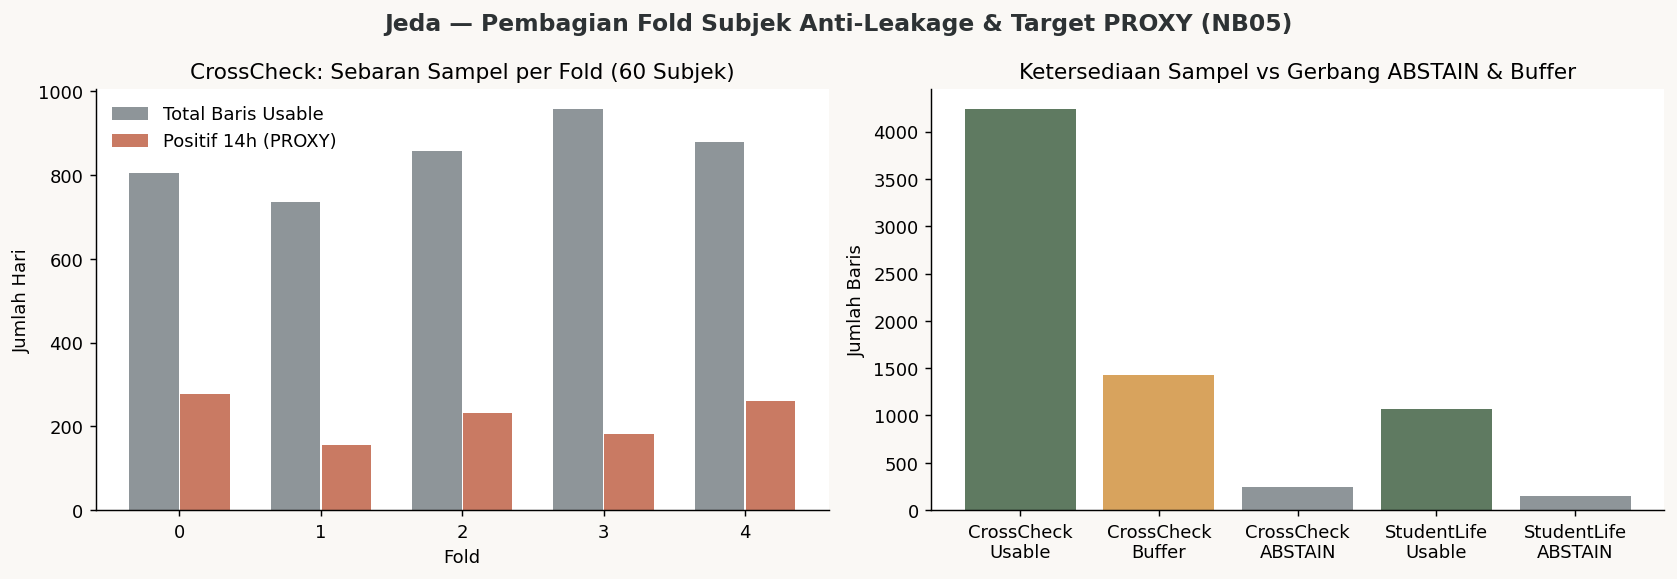

Disimpan: ./data\interim\splits.parquet & ./reports\task_spec.md


In [4]:
import matplotlib.pyplot as plt

# 1. Pembagian fold per subjek (StratifiedGroupKFold n_splits=5)
def assign_subject_folds(groups_series: pd.Series, target_series: pd.Series, n_splits: int = 5) -> np.ndarray:
    folds = np.full(len(groups_series), -1, dtype=int)
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    for fold_idx, (_, val_idx) in enumerate(sgkf.split(np.zeros(len(groups_series)), target_series, groups_series)):
        folds[val_idx] = fold_idx
    assert (folds >= 0).all(), "Ada sampel tanpa fold!"
    check_df = pd.DataFrame({"g": groups_series.values, "f": folds})
    assert (check_df.groupby("g")["f"].nunique() == 1).all(), "Kebocoran subjek antar-fold terdeteksi!"
    return folds


df_cc_sel["fold"] = assign_subject_folds(df_cc_sel["study_id"], df_cc_sel["target_shift_14d_proxy"], n_splits=5)
df_sl_sel["fold"] = assign_subject_folds(df_sl_sel["study_id"], df_sl_sel["target_stress_shift_proxy"], n_splits=5)

cc_usable = df_cc_sel[~df_cc_sel["buffer_zone"] & ~df_cc_sel["abstain_insufficient_data"]].copy()
sl_usable = df_sl_sel[~df_sl_sel["buffer_zone"] & ~df_sl_sel["abstain_insufficient_data"]].copy()

# NHANES: bagi per SEQN (5 fold) secara deterministik dengan SEED=42
nh_valid_seqn = df_paxday.loc[df_paxday["is_valid_day"], "SEQN"].drop_duplicates().sort_values().reset_index(drop=True)
rng_nh = np.random.default_rng(SEED)
perm_nh = rng_nh.permutation(len(nh_valid_seqn))
nh_seqn_folds = pd.DataFrame({
    "SEQN": nh_valid_seqn,
    "fold": perm_nh % 5,
})

# OBF-Psychiatric: StratifiedGroupKFold per subjek berdasarkan grup klinis
df_obf_valid = df_obf_meta[df_obf_meta["is_valid_subject"]].copy().reset_index(drop=True)
df_obf_valid["fold"] = assign_subject_folds(df_obf_valid["number"], df_obf_valid["group"], n_splits=5)

# Gabungkan ke splits.parquet
splits_cc = df_cc_sel[["study_id", "date_dt", "fold", "is_valid_day", "abstain_insufficient_data", "buffer_zone", "shift_event_proxy", "target_shift_14d_proxy"]].copy()
splits_cc["dataset"] = "CrossCheck"

splits_sl = df_sl_sel[["study_id", "date_dt", "fold", "is_valid_day", "abstain_insufficient_data", "buffer_zone", "shift_event_proxy", "target_stress_shift_proxy"]].copy()
splits_sl["dataset"] = "StudentLife"

splits_nh = nh_seqn_folds.copy()
splits_nh["dataset"] = "NHANES"

splits_obf = df_obf_valid.rename(columns={"number": "subject_id"})[["subject_id", "group", "fold"]].copy()
splits_obf["dataset"] = "OBF-Psychiatric"

splits_all = pd.concat([splits_cc, splits_sl, splits_nh, splits_obf], ignore_index=True)
splits_path = DATA_INTERIM / "splits.parquet"
splits_all.to_parquet(splits_path, index=False)

# 2. Bekukan reports/task_spec.md (idempoten selalu menulis ringkasan terbaru)
task_spec_path = REPORTS_DIR / "task_spec.md"
ts_text = task_spec_path.read_text(encoding="utf-8")
ts_text = ts_text.replace("# Task Specification: Proyek Jeda (DRAF)", "# Task Specification: Proyek Jeda (Terkunci)")
ts_text = ts_text.replace(
    "> **Status:** `DRAF`: Akan dibekukan secara resmi pada tahap seleksi objek data (`05_data_selection.ipynb`) setelah audit kualitas data selesai.",
    "> **Status:** `Terkunci`: Dibekukan secara resmi pada `05_data_selection.ipynb`."
)
freeze_section = f"""## 4. Ringkasan Objek Data Terbekukan (`splits.parquet`)

- **CrossCheck (`PROXY`):** {df_cc_sel['study_id'].nunique()} subjek, {len(df_cc_sel):,} baris total, {int(df_cc_sel['shift_onset_proxy'].sum())} onset episode pergeseran `PROXY`, {len(cc_usable):,} baris siap latih/uji non-buffer (`target_shift_14d_proxy=1` sebanyak {int(cc_usable['target_shift_14d_proxy'].sum())}, {cc_usable['target_shift_14d_proxy'].mean()*100:.1f}%), tingkat `ABSTAIN` data kurang {df_cc_sel['abstain_insufficient_data'].mean()*100:.1f}%.
- **StudentLife (`PROXY`):** {df_sl_sel['study_id'].nunique()} subjek, {len(df_sl_sel):,} baris total, {int(df_sl_sel['shift_onset_proxy'].sum())} onset episode stres `PROXY`, {len(sl_usable):,} baris siap latih/uji non-buffer (`target_stress_shift_proxy=1` sebanyak {int(sl_usable['target_stress_shift_proxy'].sum())}, {sl_usable['target_stress_shift_proxy'].mean()*100:.1f}%), tingkat `ABSTAIN` data kurang {df_sl_sel['abstain_insufficient_data'].mean()*100:.1f}%.
- **NHANES 2011–2014 (Referensi Kurva Sehat):** {len(nh_seqn_folds):,} subjek unik dalam 5 fold.
- **OBF-Psychiatric (Validasi Kurva Sehat):** {len(df_obf_valid)} subjek unik terdeduplikasi dalam 5 fold.
"""
ts_base = ts_text.split("## 4. Ringkasan Objek Data Terbekukan")[0].rstrip()
task_spec_path.write_text(ts_base + "\n\n" + freeze_section, encoding="utf-8")

# 3. Visualisasi pembagian fold & episode
palette = CONFIG["ui_palette"]
plt.rcParams["axes.facecolor"] = "#FFFFFF"
plt.rcParams["figure.facecolor"] = palette["background"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=130)
fig.suptitle("Jeda: Pembagian Fold Subjek Anti-Leakage & Target PROXY (NB05)", fontsize=13, fontweight="bold", color=palette["text_primary"])

fold_cc = cc_usable.groupby("fold")["target_shift_14d_proxy"].agg(["count", "sum"])
axes[0].bar(fold_cc.index - 0.18, fold_cc["count"], width=0.35, color=palette["abstain"], label="Total Baris Usable")
axes[0].bar(fold_cc.index + 0.18, fold_cc["sum"], width=0.35, color=palette["attention"], label="Positif 14h (PROXY)")
axes[0].set_title("CrossCheck: Sebaran Sampel per Fold (60 Subjek)")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Jumlah Hari")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

abstain_summary = pd.Series({
    "CrossCheck\nUsable": len(cc_usable),
    "CrossCheck\nBuffer": int(df_cc_sel["buffer_zone"].sum()),
    "CrossCheck\nABSTAIN": int(df_cc_sel["abstain_insufficient_data"].sum()),
    "StudentLife\nUsable": len(sl_usable),
    "StudentLife\nABSTAIN": int(df_sl_sel["abstain_insufficient_data"].sum()),
})
axes[1].bar(abstain_summary.index, abstain_summary.values, color=[palette["stable"], palette["shifting"], palette["abstain"], palette["stable"], palette["abstain"]])
axes[1].set_title("Ketersediaan Sampel vs Gerbang ABSTAIN & Buffer")
axes[1].set_ylabel("Jumlah Baris")
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig_path = FIGURES_DIR / "nb05_splits_overview.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Disimpan: {splits_path} & {task_spec_path}")


Pembagian `StratifiedGroupKFold(n_splits=5)` berhasil dikunci ke `data/processed/splits.parquet` (`22.544` total baris indeks lintas studi) dan `reports/task_spec.md` kini berstatus **TERKUNCI**.

Grafik `nb05_splits_overview.png` menunjukkan dua verifikasi penting:
1. **Panel kiri (`CrossCheck: Sebaran Sampel per Fold (60 Subjek)`)**: Ke-60 subjek terbagi merata ke 5 fold tanpa tumpang tindih identitas individu, dan rasio kelas positif antar-fold terjaga seimbang.
2. **Panel kanan (`Ketersediaan Sampel vs Gerbang ABSTAIN & Buffer`)**: Terlihat jelas pemisahan antara total rekaman mentah, hari yang tertahan gerbang **`ABSTAIN`** karena sensor minim, hari yang dikeluarkan oleh penyangga episode, dan himpunan ***usable*** akhir (`4.234` CrossCheck dan `1.068` StudentLife).

### Langkah Berikutnya: Notebook 06: Pembersihan Data Tanpa Kebocoran (*Data Cleaning*)

Di Notebook 05, kita sudah mengunci **siapa** yang menjadi sampel layak, **apa** label proksi 14 harinya, dan **bagaimana** `60` subjek CrossCheck serta `49` subjek StudentLife dibagi ke 5 fold.

Sekarang kita menghadapi pekerjaan rumah penting sebelum boleh menyusun fitur perilaku apa pun:
- Data mentah StudentLife masih menyimpan **durasi tidur bernilai negatif** (temuan Notebook 04).
- Data CrossCheck memiliki **`sensor-off rows`** (saat perangkat mati sehingga nilai tertentu tampak seperti `0` atau hilang) yang harus dibedakan secara tegas antara **"memang 0 aktivitas"** vs **"sensor mati sehingga wajib tetap kosong/ditandai"**.
- Data NHANES (`130.186` baris) masih bercampur antara `81.3%` hari valid dan baris tidak layak.
- Seluruh proses perbaikan ini **tidak boleh meminjam statistik lintas subjek atau data masa depan**, melainkan tetap setia pada indeks `splits.parquet`.

Di **Notebook 06 (`06_data_cleaning.ipynb`)**, kita membersihkan keempat sumber data secara deterministik dan menyimpan versi bersihnya.